In [1]:
from alpha_disc import profiles
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import simpson
from astropy import constants as const
from astropy import units as u
import urllib.request
from astropy.io import votable
from scipy.interpolate import interp1d
from astropy.io import fits

# U Gem

In [161]:
# Datos
M = 0.8 * 1.9e33  # 5 * M_sun
alpha_q = 0.01
alpha_o = 0.4
r = 1e9 #cm
Mdot_Msun_yr =  1.2e22 * 1.59e-26# masas solares por año

#profiles.Vertical_Profile(M, alpha_q, r, Teff, input='Teff', structure='BellLin', mu=0.62,n=150, add_Pi_values=True, path_dots='vs_quiescent.dat')
#profiles.Vertical_Profile(M, alpha_o, r, Teff, input='Teff', structure='BellLin', mu=0.62,n=150, add_Pi_values=True, path_dots='vs_out.dat')

#profiles.S_curve(3e3, 1e5, M, alpha_q, r, input='Teff', structure='BellLin', mu=0.62, n=200, tau_break=True, path_dots='S-curve_quiescence.dat', add_Pi_values=True, to_return= True)
#profiles.S_curve(1e4, 6e4, M, alpha_o, r, input='Teff', structure='BellLin', mu=0.62, n=200, tau_break=True, path_dots='S-curve_outburst_04_UG.dat', add_Pi_values=True, to_return= True)

#r_start, r_end = 7e8, 4.61e12
profiles.Radial_Profile(M, alpha_o, r_start, r_end, Par=Mdot_Msun_yr, input='Mdot_Msun_yr', structure='BellLin', mu=0.62, n=200, tau_break=True, path_dots='radial_struct_outburst_04_UG.dat', add_Pi_values=True)

#profiles.Radial_Profile(M, alpha, r_start, r_end, Par=1, input='Mdot_Mdot_edd', structure='BellLin', mu=0.62, n=153, tau_break=True, path_dots='radial_struct_outburst.dat', add_Pi_values=True)

### Estructura radial

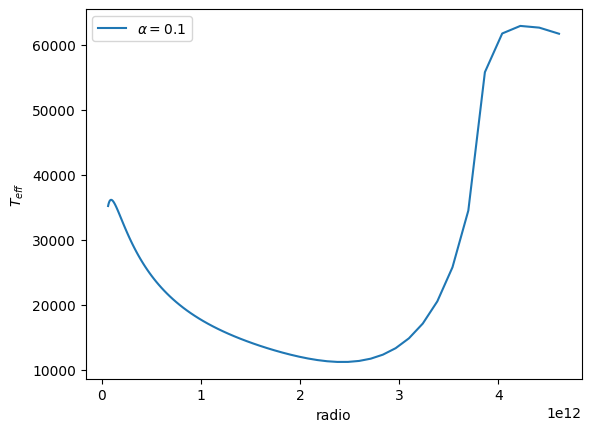

In [2]:
data_o_UG = np.loadtxt('radial_struct_outburst_UG.dat')
data_o_04_UG = np.loadtxt('radial_struct_outburst_04_UG.dat')

#r 	r/rg 	Sigma0 	Mdot 	Teff 	F 	z0r 	rho_c 	T_c 	P_c 	tau 	PradPgas_c 	varkappa_c 	Pi1 	Pi2 	Pi3 	Pi4
sigma_o_UG = [fila[2] for fila in data_o_UG] #Densidad superficial
Teff_o_UG = [fila[4] for fila in data_o_UG] #temperatura  efectiva
radio_o_UG = [fila[0] for fila in data_o_UG] #temperatura  efectiva
zor = [fila[6] for fila in data_o_UG] #temperatura  efectiva

sigma_o_04_UG = [fila[2] for fila in data_o_04_UG] #Densidad superficial
Teff_o_04_UG = [fila[4] for fila in data_o_04_UG] #temperatura  efectiva
radio_o_04_UG = [fila[0] for fila in data_o_04_UG] #temperatura  efectiva

#plt.plot(radio, Teff_q, label = r'$\alpha = 0.01$')
#plt.plot(radio_q, Teff_q, linestyle = '--', label = r'$\alpha = 0.01$')
print
plt.plot(radio_o_UG, sigma_o_UG, label = r'$\alpha = 0.1$')
plt.xlabel(r'radio')
plt.ylabel(r'$T_{eff}$')
plt.legend()

plt.show()

### Transformar a luminosidad

200 97
-2995420203.7654266


KeyboardInterrupt: 

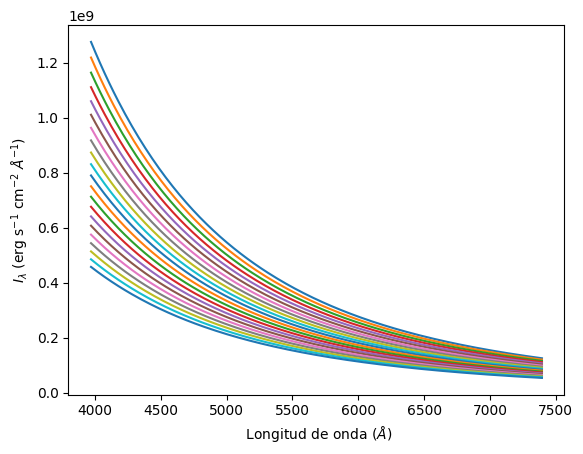

In [14]:
# constantes
h = const.h.cgs.value       
c = const.c.cgs.value       
k_B = const.k_B.cgs.value   

# rangos de ZTF
long_min = 3971
long_max = 7394.40
long = np.linspace(long_min, long_max, 200)

# Función de Planck
def planck_lambda(long, T):
    exponente = (h * c)/ (k_B*(long*1e-8)*T)
    exponente = np.clip(exponente, None, 700) 
    B = ((2 * h * (c**2)) / ((((long*1e-8)**4)*long*(np.exp(exponente) - 1.0))))
    
    plt.plot(long,B)
    plt.xlabel(r' Longitud de onda ($\AA$)')
    plt.ylabel(r'$I_\lambda$ (erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$)')
    return B


d = 1667 * 3.086e18 # en cm
i = np.radians(37.70)
R_array = np.array(radio_o_UG)
Teff_o_array = np.array(Teff_o_UG)

# deberia ser la primera temperatura con el primer radio, no el array completo 

def integrar_disco_lambda(R_array, Teff_array, long):
    print(len(long),len(Teff_array))

    F_tot = 0
    
    F_lambda = np.empty([len(Teff_array),len(long)])
    #F_lambda = np.empty([len(long),len(Teff_array)])
    
    print(R_array[0]- R_array[1])

    
    for j,t,r in zip(range(len(Teff_array[0:-1])),Teff_array[0:-1], R_array[0:-1]):
    
        
        # Calcula la funcion de planca para ese anillo
        B_R = planck_lambda(long, t)

        plt.savefig('suma_espectros.png', dpi=300, bbox_inches='tight')
        
            # Se hace el integrando
        integrando = (B_R * r**2)/2#* (R_array[j+1] - R_array[j])
        
            # Integramos numéricamente sobre el radio usando la regla de Simpson
        #integral = simpson(y=integrando, x=r
        
            # Multiplicamos por el factor
        F_lambda[j] = ((2 * np.pi* np.cos(i))*integrando / (d**2))
        #print(np.cos(i))
        #plt.plot(long,F_lambda[j])
        F_tot = F_tot + F_lambda[j]
    #plt.plot(long,F_tot)
    return F_tot

# funcion
F_lam = integrar_disco_lambda(R_array, Teff_o_array, long)

print(F_lam)

In [ ]:
def planck_lambda(long, T):
    exponente = (h*c)/(k_B*(long*1e-8)*T)
    exponente = np.clip(exponente, None, 700)

    B = (2*h*c**2)/((long*1e-8)**5 * (np.exp(exponente)-1))

    return B



F_lam = integrar_disco_lambda(R_array, Teff_o_array, long)

plt.figure(figsize=(7,5))
plt.plot(long, F_lam, lw=2)

plt.xlabel(r'Longitud de onda ($\AA$)')
plt.ylabel(r'$F_\lambda$')

plt.savefig('suma_espectros.png', dpi=300, bbox_inches='tight')
plt.show()

200 97
-2995420203.7654266


### Transformar a magnitudes

In [16]:
# Función para descargar y convertir los filtros de ZTF a frecuencias
def descargar_filtro_ztf_nu(banda):
    filter_id = f"Palomar/ZTF.{banda}_fil"
    url = f"http://svo2.cab.inta-csic.es/theory/fps/fps.php?ID={filter_id}"
    
    # Descargar el archivo VOTable e importarlo
    file_path, _ = urllib.request.urlretrieve(url)
    tabla = votable.parse_single_table(file_path)
    
    wav_angstrom = tabla.array['Wavelength']
    transmision = tabla.array['Transmission']
    
    # Convertir a cm 
    lambda_filtro = wav_angstrom 
    
    # Ordenar por frecuencia CRECIENTE para que interp1d funcione
    idx = np.argsort(lambda_filtro)
    
    return lambda_filtro[idx], transmision[idx]

# Perfiles de ZTF
nu_ztf_g, trans_ztf_g = descargar_filtro_ztf_nu('g')
nu_ztf_r, trans_ztf_r = descargar_filtro_ztf_nu('r')

# Interpolar las curvas de ZTF sobre grilla
interp_g = interp1d(nu_ztf_g, trans_ztf_g, bounds_error=False, fill_value=0.0)
interp_r = interp1d(nu_ztf_r, trans_ztf_r, bounds_error=False, fill_value=0.0)

# S_g y S_r
S_g = interp_g(long)
S_r = interp_r(long)

# Función de integración 
def integrar_filtro(F_nu, S_nu, long):
    
    y_num = (F_nu * S_nu)
    numerador = simpson(y=y_num, x=long)
    
    # Denominador
    y_den = S_nu 
    denominador = simpson(y=y_den, x=long)
    
    F_nu_mean = np.abs(numerador / denominador)  
    return F_nu_mean

# Flujos medios en cada banda
F_g = integrar_filtro(F_lam, S_g, long)
F_r = integrar_filtro(F_lam, S_r, long)

F_og = 4.74e-9
F_or = 2.64e-9

# 6. Magnitudes AB
mag_g = -2.5 * np.log10(F_g/F_og) 
mag_r = -2.5 * np.log10(F_r/F_or) 

print(f'mag AB g = {mag_g:.2f}')
print(f'mag AB r = {mag_r:.2f}')
print(f'Color g-r = {mag_g - mag_r:.2f}')

mag AB g = 4.92
mag AB r = 4.99
Color g-r = -0.07


# SU UMa

In [177]:
M = 0.8 * 1.9e33  # 5 * M_sun
alpha_q = 0.01
alpha_o = 0.4
r = 1e9 #cm
Mdot_Msun_yr =  7e20 * 1.59e-26# masas solares por año

#profiles.Vertical_Profile(M, alpha_q, r, Teff, input='Teff', structure='BellLin', mu=0.62,n=150, add_Pi_values=True, path_dots='vs_quiescent.dat')
#profiles.Vertical_Profile(M, alpha_o, r, Teff, input='Teff', structure='BellLin', mu=0.62,n=150, add_Pi_values=True, path_dots='vs_out.dat')

#profiles.S_curve(3e3, 1e5, M, alpha_q, r, input='Teff', structure='BellLin', mu=0.62, n=200, tau_break=True, path_dots='S-curve_quiescence.dat', add_Pi_values=True, to_return= True)
#profiles.S_curve(3e3, 1e5, M, alpha_o, r, input='Teff', structure='BellLin', mu=0.62, n=200, tau_break=True, path_dots='S-curve_outburst.dat', add_Pi_values=True, to_return= True)

r_start, r_end = 7e8, 2.82e10
profiles.Radial_Profile(M, alpha_o, r_start, r_end, Par=Mdot_Msun_yr, input='Mdot_Msun_yr', structure='BellLin', mu=0.62, n=200, tau_break=True, path_dots='radial_struct_outburst_04_SU.dat', add_Pi_values=True)

#profiles.Radial_Profile(M, alpha, r_start, r_end, Par=1, input='Mdot_Mdot_edd', structure='BellLin', mu=0.62, n=153, tau_break=True, path_dots='radial_struct_outburst.dat', add_Pi_values=True)

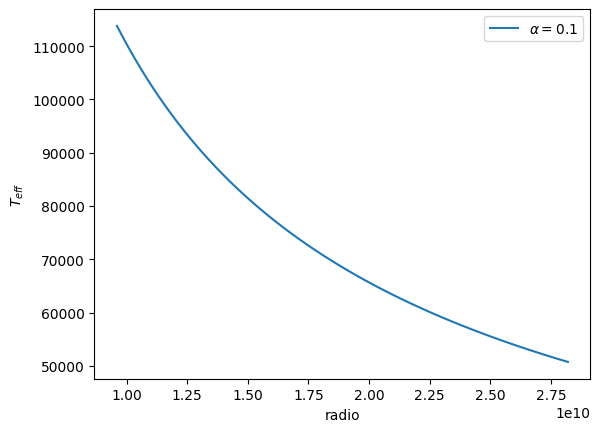

In [189]:
data_o_SU = np.loadtxt('radial_struct_outburst_SU.dat')
data_o_04_SU = np.loadtxt('radial_struct_outburst_04_SU.dat')

sigma_o_SU = [fila[2] for fila in data_o_SU] #Densidad superficial
Teff_o_SU = [fila[4] for fila in data_o_SU] #temperatura  efectiva
radio_o_SU = [fila[0] for fila in data_o_SU] #temperatura  efectiva
zor = [fila[6] for fila in data_o_SU] #temperatura  efectiva

sigma_o_04_SU = [fila[2] for fila in data_o_04_SU] #Densidad superficial
Teff_o_04_SU = [fila[4] for fila in data_o_04_SU] #temperatura  efectiva
radio_o_04_SU = [fila[0] for fila in data_o_04_SU] #temperatura  efectiva


#plt.plot(radio, Teff_q, label = r'$\alpha = 0.01$')
#plt.plot(radio_q, Teff_q, linestyle = '--', label = r'$\alpha = 0.01$')
plt.plot(radio_o_SU, Teff_o_SU, label = r'$\alpha = 0.1$')
plt.xlabel(r'radio')
plt.ylabel(r'$T_{eff}$')
plt.legend()

plt.show()

200 59
-180025465.69652367
[7.59733460e-12 7.47627900e-12 7.35761961e-12 7.24129988e-12
 7.12726479e-12 7.01546083e-12 6.90583594e-12 6.79833946e-12
 6.69292211e-12 6.58953592e-12 6.48813421e-12 6.38867155e-12
 6.29110370e-12 6.19538761e-12 6.10148135e-12 6.00934409e-12
 5.91893608e-12 5.83021859e-12 5.74315392e-12 5.65770531e-12
 5.57383699e-12 5.49151408e-12 5.41070259e-12 5.33136942e-12
 5.25348230e-12 5.17700976e-12 5.10192115e-12 5.02818658e-12
 4.95577692e-12 4.88466373e-12 4.81481933e-12 4.74621669e-12
 4.67882946e-12 4.61263194e-12 4.54759905e-12 4.48370634e-12
 4.42092995e-12 4.35924659e-12 4.29863354e-12 4.23906863e-12
 4.18053023e-12 4.12299721e-12 4.06644896e-12 4.01086535e-12
 3.95622673e-12 3.90251393e-12 3.84970821e-12 3.79779128e-12
 3.74674528e-12 3.69655276e-12 3.64719668e-12 3.59866040e-12
 3.55092765e-12 3.50398255e-12 3.45780958e-12 3.41239356e-12
 3.36771969e-12 3.32377347e-12 3.28054075e-12 3.23800769e-12
 3.19616077e-12 3.15498677e-12 3.11447277e-12 3.07460612e-

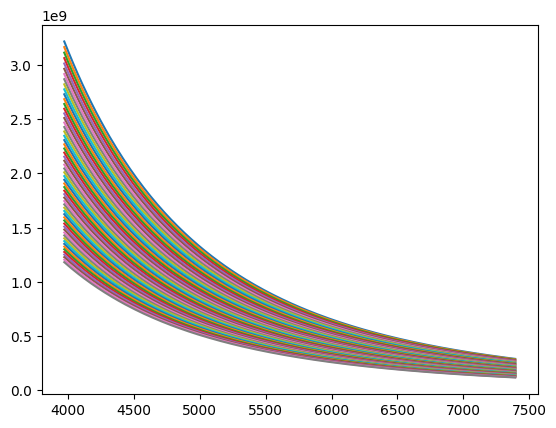

In [25]:
# constantes
h = const.h.cgs.value       
c = const.c.cgs.value       
k_B = const.k_B.cgs.value   

# rangos de ZTF
long_min = 3971
long_max = 7394.40
long = np.linspace(long_min, long_max, 200)

# Función de Planck
def planck_lambda(long, T):
    exponente = (h * c)/ (k_B*(long*1e-8)*T)
    exponente = np.clip(exponente, None, 700) 
    B = ((2 * h * (c**2)) / ((((long*1e-8)**4)*long*(np.exp(exponente) - 1.0))))
    plt.plot(long,B)
    return B


d = 1051 * 3.086e18 # en cm
i = np.radians(37.70)
R_array = np.array(radio_o_SU)
Teff_o_array = np.array(Teff_o_SU)

# deberia ser la primera temperatura con el primer radio, no el array completo 

def integrar_disco_lambda(R_array, Teff_array, long):
    print(len(long),len(Teff_array))

    F_tot = 0
    
    F_lambda = np.empty([len(Teff_array),len(long)])
    #F_lambda = np.empty([len(long),len(Teff_array)])
    
    print(R_array[0]- R_array[1])

    plt.plot

    
    for j,t,r in zip(range(len(Teff_array[0:-1])),Teff_array[0:-1], R_array[0:-1]):
    
        
        # Calcula la funcion de planca para ese anillo
        B_R = planck_lambda(long, t)
        
            # Se hace el integrando
        integrando = (B_R * r**2)/2#* (R_array[j+1] - R_array[j])
        
            # Integramos numéricamente sobre el radio usando la regla de Simpson
        #integral = simpson(y=integrando, x=r
        
            # 4. Multiplicamos por el factor
        F_lambda[j] = ((2 * np.pi* np.cos(i))*integrando) / (d**2)
        #print(np.cos(i))
        #plt.plot(long,F_lambda[j])
        F_tot = F_tot + F_lambda[j]
    #plt.plot(long,F_tot)
    return F_tot

# funcion
F_lam = integrar_disco_lambda(R_array, Teff_o_array, long)

print(F_lam)

In [26]:
# Función para descargar y convertir los filtros de ZTF a frecuencias
def descargar_filtro_ztf_nu(banda):
    filter_id = f"Palomar/ZTF.{banda}_fil"
    url = f"http://svo2.cab.inta-csic.es/theory/fps/fps.php?ID={filter_id}"
    
    # Descargar el archivo VOTable e importarlo
    file_path, _ = urllib.request.urlretrieve(url)
    tabla = votable.parse_single_table(file_path)
    
    wav_angstrom = tabla.array['Wavelength']
    transmision = tabla.array['Transmission']
    
    lambda_filtro = wav_angstrom 
    
    # Ordenar por frecuencia CRECIENTE para que interp1d funcione
    idx = np.argsort(lambda_filtro)
    
    return lambda_filtro[idx], transmision[idx]

# Perfiles de ZTF
nu_ztf_g, trans_ztf_g = descargar_filtro_ztf_nu('g')
nu_ztf_r, trans_ztf_r = descargar_filtro_ztf_nu('r')

# Interpolar las curvas de ZTF sobre grilla
interp_g = interp1d(nu_ztf_g, trans_ztf_g, bounds_error=False, fill_value=0.0)
interp_r = interp1d(nu_ztf_r, trans_ztf_r, bounds_error=False, fill_value=0.0)

# S_g y S_r
S_g = interp_g(long)
S_r = interp_r(long)

# Función de integración 
def integrar_filtro(F_nu, S_nu, long):
    
    y_num = (F_nu * S_nu)
    numerador = simpson(y=y_num, x=long)
    
    # Denominador
    y_den = S_nu 
    denominador = simpson(y=y_den, x=long)
    
    F_nu_mean = np.abs(numerador / denominador)  
    return F_nu_mean

# Flujos medios en cada banda
F_g = integrar_filtro(F_lam, S_g, long)
F_r = integrar_filtro(F_lam, S_r, long)

F_og = 4.74e-9
F_or = 2.64e-9

# 6. Magnitudes AB
mag_g = -2.5 * np.log10(F_g/F_og) 
mag_r = -2.5 * np.log10(F_r/F_or) 

print(f'mag AB g = {mag_g:.2f}')
print(f'mag AB r = {mag_r:.2f}')
print(f'Color g-r = {mag_g - mag_r:.2f}')

mag AB g = 7.70
mag AB r = 8.28
Color g-r = -0.58


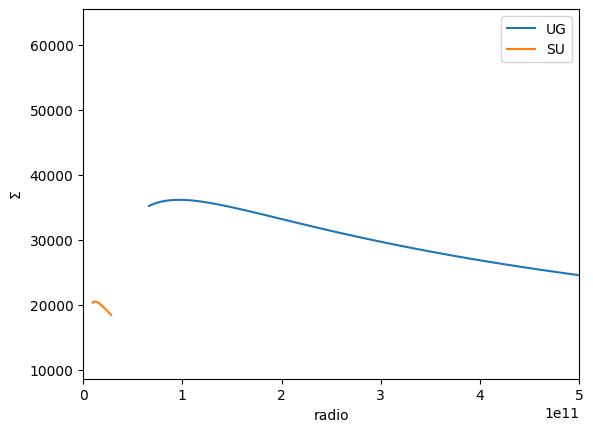

In [37]:
plt.plot(radio_o_UG, sigma_o_UG, label = 'UG')
plt.plot(radio_o_SU, sigma_o_SU, label = 'SU')
plt.xlabel(r'radio')
plt.ylabel(r'$\Sigma$')
plt.xlim(0,5e11)
plt.legend()

plt.savefig('densidad_vs_radio')

113795.8114225508 54432.29429948224


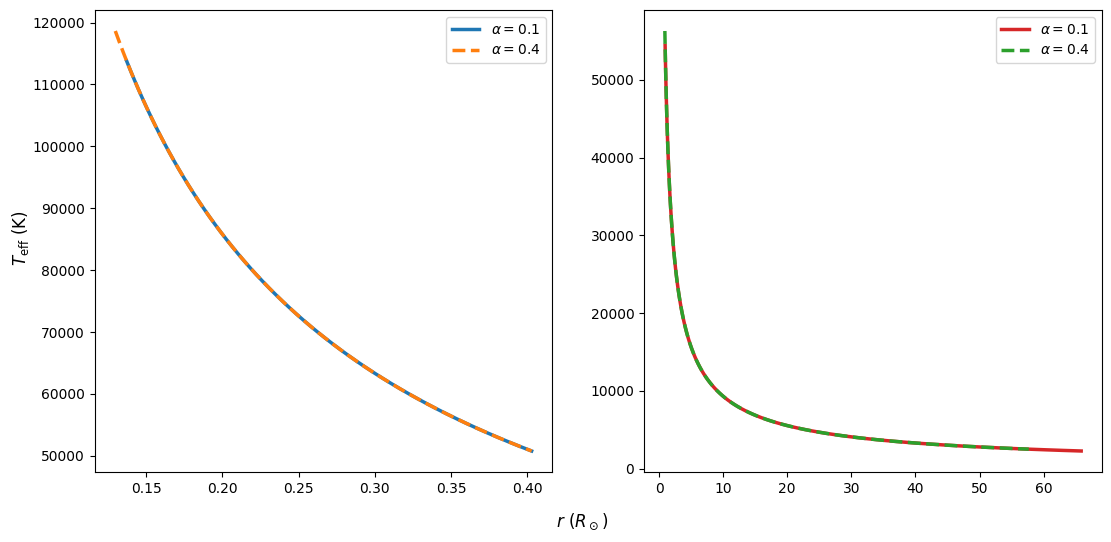

In [207]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

radio_o_SU = np.array(radio_o_SU)
radio_o_UG = np.array(radio_o_UG)
radio_o_04_UG = np.array(radio_o_04_UG)
radio_o_04_SU = np.array(radio_o_04_SU)

# Curvas
ax1.plot(radio_o_SU/7e10, Teff_o_SU, lw=2.5, label = r'$\alpha = 0.1$')
ax1.plot(radio_o_04_SU/7e10, Teff_o_04_SU, lw=2.5, label = r'$\alpha = 0.4$', linestyle='--')
ax2.plot(radio_o_UG/7e10, Teff_o_UG, color = 'tab:red',lw=2.5, label = r'$\alpha = 0.1$')
ax2.plot(radio_o_04_UG/7e10, Teff_o_04_UG,color = 'tab:green', lw=2.5, label = r'$\alpha = 0.4$', linestyle='--')

# Índices de los máximos
idx_max_SU = np.argmax(Teff_o_SU)
idx_max_UG = np.argmax(Teff_o_UG)

# Radios y temperaturas máximas
r_max_SU = radio_o_SU[idx_max_SU]
T_max_SU = Teff_o_SU[idx_max_SU]

r_max_UG = radio_o_UG[idx_max_UG]
T_max_UG = Teff_o_UG[idx_max_UG]


ax1.legend(loc ='upper right')
ax2.legend(loc ='upper right')

# Escalas


fig.supxlabel(r'$r \ (R_\odot)$')
fig.supylabel(r'$T_{\rm eff}$ (K)', x=0.06)

print(np.max(Teff_o_SU), np.max(T_max_UG))

plt.savefig('temperatura_vs_radio.png', dpi=300, bbox_inches='tight')
plt.show()

20520.943920599424 62949.380941479125


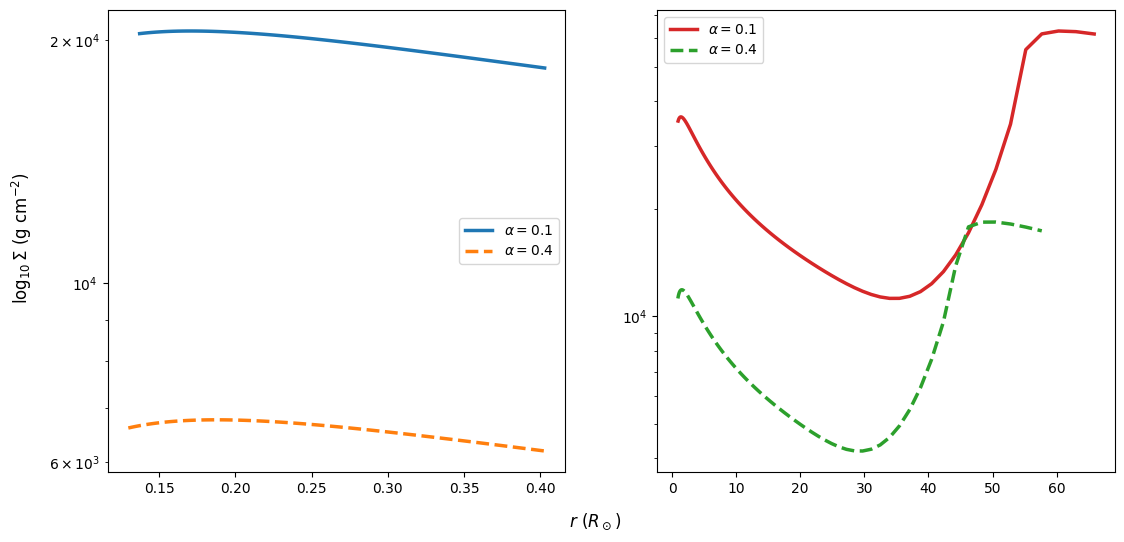

In [209]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

ax1.plot(radio_o_SU/7e10, sigma_o_SU, lw = 2.5, label = r'$\alpha= 0.1$')
ax1.plot(radio_o_04_SU/7e10, sigma_o_04_SU, lw = 2.5, label= r'$\alpha= 0.4$', linestyle='--')
ax2.plot(radio_o_UG/7e10, sigma_o_UG, color = 'tab:red', lw = 2.5, label =r'$\alpha= 0.1$')
ax2.plot(radio_o_04_UG/7e10, sigma_o_04_UG, color = 'tab:green', lw= 2.5, label = r'$\alpha = 0.4$', linestyle='--')
print(np.max(sigma_o_SU), np.max(sigma_o_UG))
ax1.set_yscale('log')
ax2.set_yscale('log')

ax1.legend()
ax2.legend()

fig.supxlabel(r'$ r \ (R_\odot)$')
fig.supylabel(r'$\log_{10} \Sigma$ (g cm$^{-2}$)', x= 0.05)

plt.savefig('densidad_vs_radio.png', dpi=300,bbox_inches='tight')

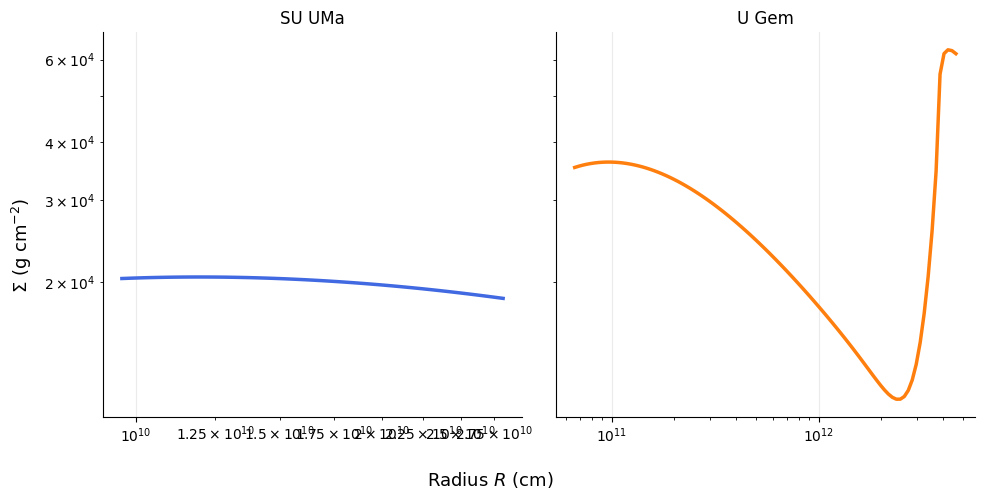

In [60]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(10, 5),
    sharey=True
)

ax1.plot(radio_o_SU, sigma_o_SU,
         color='royalblue',
         lw=2.5)

ax2.plot(radio_o_UG, sigma_o_UG,
         color='tab:orange',
         lw=2.5)

ax1.set_title('SU UMa')
ax2.set_title('U Gem')

for ax in (ax1, ax2):
    ax.set_xscale('log')
    ax.set_yscale('log')      # si corresponde
    ax.grid(alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.supxlabel(r'Radius $R$ (cm)', fontsize=13)
fig.supylabel(r'$\Sigma$ (g cm$^{-2}$)', fontsize=13)

plt.tight_layout()
plt.show()

### Estructura vertical

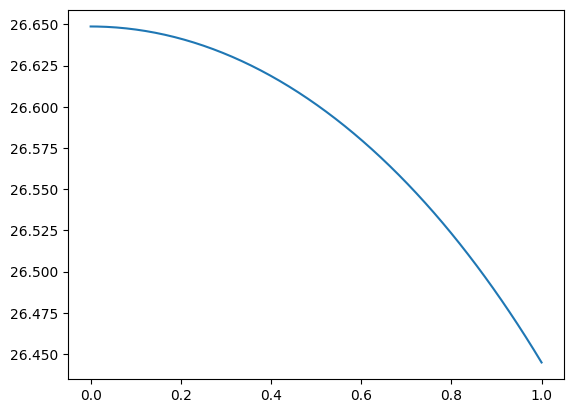

In [24]:
vertical_quiensence = np.loadtxt('vs_quiescent.dat')
vertical_outburst = np.loadtxt('vs_out.dat')

# t	 S	 P	 Q	 T	 rho	 varkappa	 tau	 grad
# S, P, Q, T -- normalised values, rho -- in g/cm^3, varkappa -- in cm^2/g 

flujo_q = [fila[3] for fila in vertical_quiensence]
T_vertical_q = [fila[4] for fila in vertical_outburst]


plt.plot(flujo_q)

In [335]:
from alpha_disc import profiles

#help(profiles)
#help(profiles.Vertical_Profile)
#help(profiles.S_curve)
help(profiles.Radial_Profile)

Help on function Radial_Profile in module alpha_disc.profiles:

Radial_Profile(M, alpha, r_start, r_end, Par, input, structure, mu=0.6, abundance='solar', F_in=0, nu_irr=None, L_X_irr=None, spectrum_irr=None, spectrum_irr_par=None, args_spectrum_irr=(), kwargs_spectrum_irr={}, cos_theta_irr=None, cos_theta_irr_exp=0.08333333333333333, C_irr=None, T_irr=None, z0r_start_estimation=None, Sigma0_start_estimation=None, P_ph_0=None, verbose=False, verbose_rad=False, to_return=False, to_save=True, n=100, tau_break=True, add_Pi_values=True, path_dots=None, magn_args=None, rad_pressure_include=True)
    Calculates radial structure of disc. Return table, which contains input parameters of the system,
    surface density Sigma0, viscous torque F, accretion rate Mdot, effective temperature Teff
    (or Tvis in case of external irradiation), geometrical half-thickness of the disc z0r and
    parameters in the symmetry plane of disc as functions of radius.

    Parameters
    ----------
    M : doub